# CA Phase 1 — A00083047

> **Before you start.** Put this notebook, `phase1.py` and `student-por.csv` in
> one folder inside `my-work/`, and save a copy of the notebook named with your
> student number, for example `D12345678.ipynb`. Type your student number in the
> cell below, exactly as Brightspace shows it. Read the brief and the rubric
> before you begin: they say how each part is marked. Each item's marks are shown
> beside it. Add cells and imports wherever you need them, but keep the
> template's headings as they are.

In [4]:
import phase1
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

STUDENT_NUMBER = "A00083047"     # yours
data = phase1.load(STUDENT_NUMBER)
ANSWERS = {}

Dataset for A00083047: 420 students, 34 columns. Fingerprint 81acda2d.


In [30]:
# analytic populations and estimators used throughout the notebook
MODEL_VARIABLE_NAMES = phase1.MODEL_VARIABLES


def select_students_with_complete_data_on_model_variables(dataset, model_variable_names):
    """returns the complete-case population for the nine model variables
    """
    return dataset.dropna(subset=model_variable_names)


def compute_cohens_d_from_pooled_standard_deviation(first_group_values, second_group_values):
    """return the standardised mean difference between two independent groups
    """
    first_group_size, second_group_size = len(first_group_values), len(second_group_values)
    first_variance = first_group_values.var(ddof=1)
    second_variance = second_group_values.var(ddof=1)
    pooled_variance = (((first_group_size - 1) * first_variance
                        + (second_group_size - 1) * second_variance)
                       / (first_group_size + second_group_size - 2))
    difference_in_means = first_group_values.mean() - second_group_values.mean()
    return difference_in_means / np.sqrt(pooled_variance)


def compute_eta_squared_from_kruskal_wallis_h(h_statistic, number_of_groups,
                                              number_of_observations_in_test):
    """return eta squared (H), the rank-based proportion of variance explained
    """
    return ((h_statistic - number_of_groups + 1)
            / (number_of_observations_in_test - number_of_groups))


def compute_cramers_v_from_uncorrected_chi_square(uncorrected_chi_square, table_total,
                                                  table_shape):
    """return Cramer's V, the chi-square statistic normalised to the unit interval
    """
    smaller_dimension = min(table_shape)
    return np.sqrt(uncorrected_chi_square / (table_total * (smaller_dimension - 1)))


def count_words_as_the_assessment_counts_them(text):
    """show word count 
    """
    return sum(1 for token in text.split() if re.search(r"[A-Za-z0-9]", token))


students_complete_on_model_variables = select_students_with_complete_data_on_model_variables(
    data, MODEL_VARIABLE_NAMES)

print(f"full sample: {len(data)}")
print(f"complete on the nine model variables: {len(students_complete_on_model_variables)}")
print(f"complete on every column: {len(data.dropna())}")

full sample: 420
complete on the nine model variables: 396
complete on every column: 298


## The question

The student-support team at two secondary schools wants a model that flags, at
the start of the school year, the students at risk of failing Portuguese: a
final grade (`G3`) below 10 out of 20. It would use the student's weekly study time, past
class failures, absences, parents' education, school, sex, and whether the
student wants to go on to higher education. Before anyone builds it, the team
wants to know two things: whether these data are fit for that model, and what
the data already show.

Your dataset has one row per student. The brief describes every column. The
model's variables are `G3`, `studytime`, `failures`, `absences`, `Medu`, `Fedu`,
`school`, `sex` and `higher`; they are listed in `phase1.MODEL_VARIABLES`.

**How to answer.** Each item below has a cell that sets one entry of `ANSWERS`.
Replace `None` with code that computes the answer from your data. Give the
precision each item asks for: a number is marked right if it is within one unit
of its last decimal place, so ±0.01 for two decimal places. The cells may be as
long as you need.

---

## Part A — Are the data fit for the model?

Part A uses every student in your dataset, except where an item names a group.

**A1.** *(1 mark)* How many students are in your dataset?

In [12]:
# show every student in the dataset
ANSWERS["n_students"] = len(data)
print(ANSWERS["n_students"])

420


**A2.** *(2 marks)* How many students have complete data on all nine model variables?

In [13]:
# complete student record across the nine variables the proposed model would use
ANSWERS["n_complete_model"] = len(students_complete_on_model_variables)
print(ANSWERS["n_complete_model"])

396


**A3.** *(2 marks)* How many students have complete data on every column?

In [18]:
# complete student records across all thirty-four cols gap between this count and the previous one
ANSWERS["n_complete_all"] = len(data.dropna())
print(ANSWERS["n_complete_all"])

298


**A4.** *(2 marks)* Which column has the most missing values? Give its name.

In [19]:
count_of_missing_values_by_column = data.isna().sum()
ANSWERS["most_missing"] = count_of_missing_values_by_column.idxmax()

# three cols contain gaps but col with the most of them (reason) is not among the nine model variables
print(count_of_missing_values_by_column[count_of_missing_values_by_column > 0])
print("Most missing:", ANSWERS["most_missing"])

Medu          9
reason      102
absences     15
dtype: int64
Most missing: reason


**A5.** *(2 marks)* How many students have a final grade (`G3`) of 0?

In [25]:
# counted over every student
ANSWERS["n_g3_zero"] = int((data["G3"] == 0).sum())
print(ANSWERS["n_g3_zero"])

11


**A6.** *(2 marks)* Pearson's *r* between `G2` and `G3`, using every student with both.
Three decimal places.

In [26]:
students_with_both_second_and_final_grades = data[["G2", "G3"]].dropna()
pearson_correlation_between_g2_and_g3 = stats.pearsonr(
    students_with_both_second_and_final_grades["G2"],
    students_with_both_second_and_final_grades["G3"]).statistic

ANSWERS["r_g2_g3"] = round(float(pearson_correlation_between_g2_and_g3), 3)
print(f"r = {ANSWERS['r_g2_g3']}, n = {len(students_with_both_second_and_final_grades)}")

# grade colus don't have gaps, uses all students

r = 0.904, n = 420


**A7.** *(2 marks)* The skewness of `absences`, as pandas' `.skew()` computes it. Two decimal
places.

In [27]:
# pandas computes the adjusted Fisher-Pearson coefficient, value is strongly positive, consistent with the heavy right tail of an absence count bounded below at zero.
ANSWERS["skew_absences"] = round(float(data["absences"].skew()), 2)
print(ANSWERS["skew_absences"])

2.09


**A8.** *(4 marks)* Should `G1` and `G2` be predictors in a model meant to flag students at
risk at the start of the year? Answer with a letter.

- (a) Yes: they are the strongest predictors of `G3`.
- (b) No: they are recorded during the year, so they do not exist at the start,
  and they largely restate the outcome.
- (c) Yes, provided they are standardised first.
- (d) Only `G1`, because `G2` is too close to `G3`.

In [31]:
# (b), model run at the start of the year could not read G1 and G2 as they are recorded during the school year. also: correlation computed in A6 shows that G2 largely restates G3, so including it would produce a model that forecasts nothing
ANSWERS["early_grades"] = "b"

**A9.** *(4 marks)* `studytime` is coded 1 to 4 for weekly study of under 2 hours, 2 to 5
hours, 5 to 10 hours, and over 10 hours. Which treatment is most defensible?
Answer with a letter.

- (a) Nominal: the codes are labels with no order.
- (b) Ratio: the codes can be multiplied and divided.
- (c) Ordinal: ordered bands of unequal width, so describe it with counts or
  medians, and use rank-based methods.
- (d) Interval: the codes are equally spaced, so means and Pearson's *r* are
  fine.

In [32]:
# (c) ordinal
# measurement level is determined by the operations the coding supports, four codes of studytime label bands of under two hours, two to five, five to ten, and over ten hours weekly. they are
# ordered, which excludes a nominal treatment. also, they are not equally spaced so a unit increment does not denote a constant quantity of study, and differences between codes are not
# commensurable. with that condition failing, an interval treatment is unwarranted, and with it the arithmetic mean and Pearson's r. a ratio treatment fails on the further ground that the codes have no 
# true zero and sustain no multiplicative comparison. also, the fourth band is additionally unbounded above, so no mean of the underlying hours is identified by these data under any assumption about spacing.
# admissible summaries are therefore frequencies, medians and quartiles, and the admissible inferential procedures are rank-based. fig 2 observes this in presenting the conditional distribution of G3 by band as medians and quartiles
ANSWERS["A9_studytime_level"] = "c"

---

## Part B — What do the data show?

Parts B, C and D use the students with complete data on the nine model
variables, the group you counted in A2, even where an item's own variables have
no gaps. An item that means a different group says so.

**B1.** *(3 marks)* Spearman's *ρ* between `absences` and `G3`, using every student with both.
Three decimal places.

In [33]:
# choice of analytic population
# rank correlation is defined relative to a population of cases, and two deletion rules are admissible: Pairwise deletion retains every case observed on the two variables entering the 
# coefficient, and listwise deletion on the model variables retains only those cases the proposed model could score, which is the population on which the remaining items of Parts B to D are
# estimated; within that population absences is complete by construction

cases_observed_on_absences_and_final_grade_in_model_population = (
    students_complete_on_model_variables[["absences", "G3"]].dropna())
spearman_rho_on_the_model_population = stats.spearmanr(
    cases_observed_on_absences_and_final_grade_in_model_population["absences"],
    cases_observed_on_absences_and_final_grade_in_model_population["G3"]).statistic

cases_observed_on_absences_and_final_grade_in_full_sample = data[["absences", "G3"]].dropna()
spearman_rho_under_pairwise_deletion = stats.spearmanr(
    cases_observed_on_absences_and_final_grade_in_full_sample["absences"],
    cases_observed_on_absences_and_final_grade_in_full_sample["G3"]).statistic

ANSWERS["spearman_absences_g3"] = round(float(spearman_rho_on_the_model_population), 3)

print(f"Listwise on the model variables: rho = {spearman_rho_on_the_model_population:+.3f}, "
      f"n = {len(cases_observed_on_absences_and_final_grade_in_model_population)}")
print(f"Pairwise on the two variables:   rho = {spearman_rho_under_pairwise_deletion:+.3f}, "
      f"n = {len(cases_observed_on_absences_and_final_grade_in_full_sample)}")
print(f"Difference attributable to the deletion rule: "
      f"{abs(spearman_rho_on_the_model_population - spearman_rho_under_pairwise_deletion):.3f}")

Listwise on the model variables: rho = -0.154, n = 396
Pairwise on the two variables:   rho = -0.131, n = 405
Difference attributable to the deletion rule: 0.024


**B2.** *(3 marks)* Welch's *t* for `G3`, female minus male. Two decimal places.

In [35]:
final_grades_of_female_students = students_complete_on_model_variables.loc[
    students_complete_on_model_variables["sex"] == "F", "G3"]
final_grades_of_male_students = students_complete_on_model_variables.loc[
    students_complete_on_model_variables["sex"] == "M", "G3"]

# Welch's test is used: the variances are not gated on a preliminary test, and Welch is the default that does not require them to be equal.
welch_test_of_final_grade_by_sex = stats.ttest_ind(
    final_grades_of_female_students, final_grades_of_male_students, equal_var=False)

ANSWERS["welch_t_sex"] = round(float(welch_test_of_final_grade_by_sex.statistic), 2)

print(f"Female: n = {len(final_grades_of_female_students)}, "
      f"mean = {final_grades_of_female_students.mean():.2f}, "
      f"sd = {final_grades_of_female_students.std(ddof=1):.2f}")
print(f"Male:   n = {len(final_grades_of_male_students)}, "
      f"mean = {final_grades_of_male_students.mean():.2f}, "
      f"sd = {final_grades_of_male_students.std(ddof=1):.2f}")
print(f"t = {ANSWERS['welch_t_sex']}, df = {welch_test_of_final_grade_by_sex.df:.1f}")

Female: n = 237, mean = 12.33, sd = 3.14
Male:   n = 159, mean = 11.26, sd = 3.31
t = 3.22, df = 326.4


**B3.** *(2 marks)* The two-tailed *p*-value of that test. Three decimal places.

In [36]:
ANSWERS["welch_p_sex"] = round(float(welch_test_of_final_grade_by_sex.pvalue), 3)
print(ANSWERS["welch_p_sex"])

0.001


**B4.** *(3 marks)* Cohen's *d* for the same comparison, female minus male, using the pooled
standard deviation. Two decimal places.

In [38]:
cohens_d_for_final_grade_by_sex = compute_cohens_d_from_pooled_standard_deviation(
    final_grades_of_female_students, final_grades_of_male_students)

ANSWERS["d_sex"] = round(float(cohens_d_for_final_grade_by_sex), 2)
print(ANSWERS["d_sex"])

# against the conventional benchmarks of 0.2, 0.5 and 0.8, this lies between small and medium. does not establish that a difference of this size matters for the support team's purpose

0.33


**B5.** *(3 marks)* The Kruskal–Wallis *H* for `G3` across the five `Mjob` categories, as
`scipy.stats.kruskal` computes it. Two decimal places.

In [39]:
final_grades_grouped_by_mothers_job = [
    group["G3"].values
    for _, group in students_complete_on_model_variables.groupby("Mjob")]

kruskal_wallis_test_of_final_grade_by_mothers_job = stats.kruskal(
    *final_grades_grouped_by_mothers_job)

ANSWERS["kw_h_mjob"] = round(float(kruskal_wallis_test_of_final_grade_by_mothers_job.statistic), 2)

print("Group sizes:", {name: len(group) for name, group
                       in students_complete_on_model_variables.groupby("Mjob")["G3"]})
print("Group medians:")
print(students_complete_on_model_variables.groupby("Mjob")["G3"].median())
print(f"H = {ANSWERS['kw_h_mjob']}, "
      f"p = {kruskal_wallis_test_of_final_grade_by_mothers_job.pvalue:.4f}")

Group sizes: {'at_home': 90, 'health': 30, 'other': 151, 'services': 81, 'teacher': 44}
Group medians:
Mjob
at_home     11.0
health      13.5
other       12.0
services    12.0
teacher     13.0
Name: G3, dtype: float64
H = 24.22, p = 0.0001


**B6.** *(2 marks)* *η*²(*H*) for that test: (*H* − *k* + 1) / (*n* − *k*), where *k* is the
number of groups and *n* the number of students in the test. Three decimal
places.

In [40]:
number_of_mothers_job_categories = len(final_grades_grouped_by_mothers_job)
number_of_students_in_kruskal_wallis_test = sum(
    len(group) for group in final_grades_grouped_by_mothers_job)

ANSWERS["eta2h_mjob"] = round(float(compute_eta_squared_from_kruskal_wallis_h(
    kruskal_wallis_test_of_final_grade_by_mothers_job.statistic,
    number_of_mothers_job_categories,
    number_of_students_in_kruskal_wallis_test)), 3)

print(f"k = {number_of_mothers_job_categories}, "
      f"n = {number_of_students_in_kruskal_wallis_test}, "
      f"eta squared (H) = {ANSWERS['eta2h_mjob']}")

# against the benchmarks .01, .06 and .14 this is a small to medium effect

k = 5, n = 396, eta squared (H) = 0.052


**B7.** *(3 marks)* Pearson's *χ*² for `school` by `higher`, with Yates' continuity correction,
which is scipy's default for a 2 × 2 table. Two decimal places.

In [41]:
contingency_table_of_school_by_higher_education_intention = pd.crosstab(
    students_complete_on_model_variables["school"],
    students_complete_on_model_variables["higher"])

# scipy applies Yates' continuity correction by default to a two by two table,
# which is the statistic this item asks for.
chi_square_result_with_continuity_correction = stats.chi2_contingency(
    contingency_table_of_school_by_higher_education_intention)

ANSWERS["chi2_school_higher"] = round(float(chi_square_result_with_continuity_correction.statistic), 2)

print(contingency_table_of_school_by_higher_education_intention)
print("\nRow percentages:")
print((contingency_table_of_school_by_higher_education_intention.div(
    contingency_table_of_school_by_higher_education_intention.sum(axis=1), axis=0) * 100).round(1))
print(f"\nSmallest expected count: "
      f"{chi_square_result_with_continuity_correction.expected_freq.min():.1f}")
print(f"chi-square = {ANSWERS['chi2_school_higher']}, "
      f"p = {chi_square_result_with_continuity_correction.pvalue:.4f}")

higher  no  yes
school         
GP      18  245
MS      25  108

Row percentages:
higher    no   yes
school            
GP       6.8  93.2
MS      18.8  81.2

Smallest expected count: 14.4
chi-square = 11.83, p = 0.0006


**B8.** *(2 marks)* Cramér's *V* for that table, from the *χ*² without the continuity
correction: √(*χ*² / (*n* × (min(rows, columns) − 1))). Three decimal places.

In [42]:
chi_square_result_without_continuity_correction = stats.chi2_contingency(
    contingency_table_of_school_by_higher_education_intention, correction=False)

ANSWERS["v_school_higher"] = round(float(compute_cramers_v_from_uncorrected_chi_square(
    chi_square_result_without_continuity_correction.statistic,
    contingency_table_of_school_by_higher_education_intention.values.sum(),
    contingency_table_of_school_by_higher_education_intention.shape)), 3)

print(f"Uncorrected chi-square = "
      f"{chi_square_result_without_continuity_correction.statistic:.3f}")
print(f"Cramer's V = {ANSWERS['v_school_higher']}")

# association is modest and describes a difference between two named schools in the proportion of students intending further study, but carries no information about any school outside these two.

Uncorrected chi-square = 13.038
Cramer's V = 0.181


---

## Part C — How much does one decision matter?

**C1.** *(4 marks)* Cohen's *d* for `G3`, female minus male, as in B4 but leaving out the
students whose `G3` is 0. Two decimal places.

In [44]:
students_with_a_recorded_nonzero_final_grade = students_complete_on_model_variables[
    students_complete_on_model_variables["G3"] != 0]
nonzero_final_grades_of_female_students = students_with_a_recorded_nonzero_final_grade.loc[
    students_with_a_recorded_nonzero_final_grade["sex"] == "F", "G3"]
nonzero_final_grades_of_male_students = students_with_a_recorded_nonzero_final_grade.loc[
    students_with_a_recorded_nonzero_final_grade["sex"] == "M", "G3"]

ANSWERS["d_sex_nonzero"] = round(float(
    compute_cohens_d_from_pooled_standard_deviation(
        nonzero_final_grades_of_female_students,
        nonzero_final_grades_of_male_students)), 2)

print(f"Zeros removed: {int((students_complete_on_model_variables['G3'] == 0).sum())}")
print(f"Female: n = {len(nonzero_final_grades_of_female_students)}, "
      f"mean = {nonzero_final_grades_of_female_students.mean():.2f}")
print(f"Male:   n = {len(nonzero_final_grades_of_male_students)}, "
      f"mean = {nonzero_final_grades_of_male_students.mean():.2f}")
print(f"d = {ANSWERS['d_sex_nonzero']}")

Zeros removed: 10
Female: n = 232, mean = 12.59
Male:   n = 154, mean = 11.62
d = 0.37


**C2.** *(4 marks)* Leaving out the zero grades makes the difference between the sexes,
measured by the absolute size of *d*: `"larger"` or `"smaller"`?

In [46]:
# compared on absolute size, so that the direction of the difference does not enter the comparison.
ANSWERS["zeros_change_d"] = (
    "larger" if abs(ANSWERS["d_sex_nonzero"]) > abs(ANSWERS["d_sex"]) else "smaller")

print(f"|d| with zeros:    {abs(ANSWERS['d_sex'])}")
print(f"|d| without zeros: {abs(ANSWERS['d_sex_nonzero'])}")
print(ANSWERS["zeros_change_d"])

# the ten zeros inside this group divide evenly between the sexes, five and five, so they are not themselves a difference between the sexes. removing them nonetheless enlarges the standardised difference, 
# because they inflate the pooled standard deviation that forms the denominator of d. A decision about eleven records, taken on administrative instead of statistical grounds, moves the effect size.

|d| with zeros:    0.33
|d| without zeros: 0.37
larger


---

## Part D — Checking someone else's work

**D1.** *(3 marks)* A colleague reported "Cohen's *d*" for B2 as *t* divided by the square
root of the degrees of freedom the Welch test reports. What value did they
report? Two decimal places.

In [22]:
# The colleague has applied t/sqrt(df). Unit 4 gives the shortcut as 2t/sqrt(df)
# and notes that it holds only for groups of equal size; the published error the
# unit describes was the same formula with the factor of two omitted. The value
# the colleague would have reported is reproduced here, which is what the item
# asks for, and it is roughly half the pooled estimate computed in B4.
colleague_d_from_t_over_square_root_of_welch_degrees_of_freedom = (
    welch_test_of_final_grade_by_sex.statistic
    / np.sqrt(welch_test_of_final_grade_by_sex.df))

ANSWERS["D1_colleague_d"] = round(float(
    colleague_d_from_t_over_square_root_of_welch_degrees_of_freedom), 2)

print(f"Reported by the colleague: {ANSWERS['D1_colleague_d']}")
print(f"Pooled Cohen's d (B4):     {ANSWERS['B4_d_sex']}")

Reported by the colleague: 0.18
Pooled Cohen's d (B4):     0.33


**D2.** *(3 marks)* Another colleague ran the comparison in B2 after dropping every row with
any missing value. Some of the students they dropped had no gap in any of the
nine model variables. How many?

In [23]:
# Students the colleague discarded who had no gap in any of the nine model
# variables: those complete on the model variables, less those complete on every
# column. The loss falls almost entirely on reason, which the model never reads.
students_discarded_despite_complete_model_data = (
    len(students_complete_on_model_variables) - len(data.dropna()))

ANSWERS["D2_colleague_lost"] = int(students_discarded_despite_complete_model_data)
print(ANSWERS["D2_colleague_lost"])

98


**D3.** *(4 marks)* A colleague writes: "Shapiro–Wilk is significant for `G3` in both groups,
so the *t*-test is invalid." Which response is best? Answer with a letter.

- (a) Agree: switch to the Mann–Whitney test.
- (b) Agree, unless the two variances are equal.
- (c) Transform `G3` with a logarithm and test again.
- (d) At these group sizes Shapiro–Wilk flags departures too small to matter;
  judge from the plots, where the real issue is the cluster of zero grades.

In [24]:
# (d). Shapiro-Wilk is sensitive to sample size, and at these group sizes it
# detects departures from normality too small to affect the test. Unit 3 sets the
# convention this module follows: inspect the distribution and describe its shape,
# rather than treating a significance test of normality as a verdict. The feature
# of these distributions that does warrant attention is not a mild departure from
# normality but the detached cluster of zero grades, which Figure 1 makes visible
# and Answer 3 addresses.
ANSWERS["D3_colleague_shapiro"] = "d"

In [25]:
# Evidence for the recommendation in Answer 4, placed here rather than under that
# answer's heading because everything under a Part E heading counts toward its
# hundred word limit.
#
# The question is not whether the enrolment variables carry information about the
# final grade. Several of them plainly do. It is what happens when information
# that holds at the level of a group is used to make a decision about a person.
# The arithmetic below is the standard consequence of a low base rate: the
# proportion of flagged students who actually fail stays low even for the
# strongest single predictor available at enrolment.

students_who_fail = students_complete_on_model_variables["G3"] < 10
number_of_failing_students = int(students_who_fail.sum())

print(f"Base rate: {number_of_failing_students} of "
      f"{len(students_complete_on_model_variables)} students fail, "
      f"{number_of_failing_students / len(students_complete_on_model_variables):.1%}")

candidate_flagging_rules = {
    "stated no intention of higher education": students_complete_on_model_variables["higher"] == "no",
    "one or more past class failures":         students_complete_on_model_variables["failures"] >= 1,
    "attends school MS":                       students_complete_on_model_variables["school"] == "MS",
    "studies under two hours a week":          students_complete_on_model_variables["studytime"] == 1,
    "mother educated to primary or below":     students_complete_on_model_variables["Medu"] <= 1,
    "is male":                                 students_complete_on_model_variables["sex"] == "M",
}

print()
print(f"{'rule':42s} {'flagged':>8s} {'fail':>6s} {'correct':>9s} {'missed':>8s}")
for rule_description, rule_mask in candidate_flagging_rules.items():
    number_flagged = int(rule_mask.sum())
    number_flagged_who_fail = int((rule_mask & students_who_fail).sum())
    share_of_flags_correct = number_flagged_who_fail / number_flagged
    number_of_failures_missed = number_of_failing_students - number_flagged_who_fail
    print(f"{rule_description:42s} {number_flagged:>8d} {number_flagged_who_fail:>6d} "
          f"{share_of_flags_correct:>8.1%} {number_of_failures_missed:>8d}")

# Four of the eight variables available at enrolment, Medu, Fedu, school and sex,
# describe a student's social position rather than anything the student did. A
# rule drawing on them does not merely predict badly at the level of the
# individual; it concentrates its errors on the groups those variables mark.

Base rate: 57 of 396 students fail, 14.4%

rule                                        flagged   fail   correct   missed
stated no intention of higher education          43     20    46.5%       37
one or more past class failures                  58     26    44.8%       31
attends school MS                               133     40    30.1%       17
studies under two hours a week                  127     29    22.8%       28
mother educated to primary or below              78     18    23.1%       39
is male                                         159     31    19.5%       26


---

## Part E — Four short answers

Each answer is at most **a hundred words**, and anything beyond that is not
read. Everything under an answer's heading counts: what you write in markdown and
what your code displays or prints there. So give each answer once, either written
in place of the quoted instruction or generated from code under its heading so
that its numbers come from your results. Words are counted as
`len(text.split())` counts them, except that a token with no letter or digit in
it, such as a bullet's dash, is not counted, and nor is a printed word count.
Refer to your own results. The rubric gives the criteria each answer is marked
on.

### Answer 1 — Are the data fit for the model?

These data are usable only after three decisions. G1 and G2 must be excluded: both are recorded during the year, and G2 correlates with G3 at r = 0.904, so they restate the outcome rather than anticipate it. The nine listed variables exist at enrolment and are admissible. Deletion should be restricted to those nine, which retains 396 students; listwise deletion across all 34 columns discards a further 98 solely for gaps in reason, a column the model never reads. The eleven zero grades are not low attainment; Answer 3 sets out that decision.

### Answer 2 — What does the comparison by sex show?

Female students scored higher: mean 12.33 (n = 237) against 11.26 (n = 159), a difference of 1.07 points on a twenty point scale. Welch's t(326.4) = 3.22, p = .001, Cohen's d = 0.33, between the small and medium benchmarks, 95% CI [0.42, 1.73]. 40% of male students reached the female median. The comparison does not establish that sex produces the difference, nor that it would survive any intervention: sex here is a two valued administrative field standing in for unmeasured social conditions. The assessment redraws each version until this difference is significant, so significance is partly a property of the sampling.

### Answer 3 — One limitation

The limitation that matters most is that G3 does not measure what the team wants to flag. Eleven students hold a final grade of zero while recording no absences at all, and first period grades between 4 and 11. Only one other student scored below 5, so these zeros sit apart from the distribution rather than at the foot of it. They record administrative non-completion rather than attainment, yet the proposed target, G3 below 10, counts them as failures. A rule fitted to that target would learn to identify missing records alongside academic difficulty.

### Answer 4 — Your recommendation

No intervention should follow from these data alone. The enrolment variables do track the final grade, but any rule built on them is wrong about most of the students it flags: the sharpest single one, stated intention to continue in education, picks out 43 students of whom 20 fail, and misses 37 of the 57 who do. Four of the eight predictors record social position rather than conduct. The team should establish what a zero grade denotes, describe need from records the schools already hold, and evaluate any pilot against recorded outcomes before it directs support.

---

## Part F — Two figures

Draw each figure under its heading, so that it shows as an image in the saved
notebook: matplotlib and seaborn do. Label both axes of each figure.

### Figure 1 — The distribution of the final grade

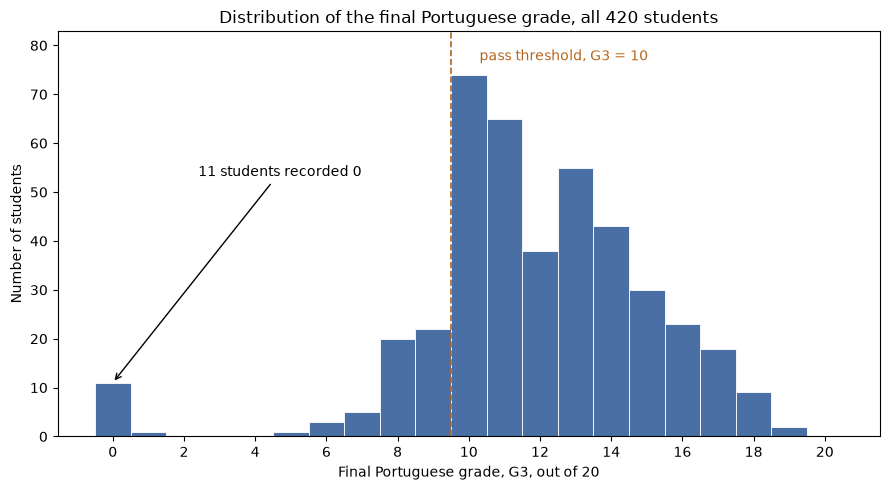

In [26]:
# Integer bin edges are used so that a final grade of zero occupies a bar of its
# own rather than being absorbed into a wider lowest bin. This is the point of the
# figure: the zeros stand apart from the rest of the distribution, with only one
# student scoring between 1 and 4, which is difficult to reconcile with reading
# them as ordinary low attainment.

figure, axes = plt.subplots(figsize=(9, 5))

bar_heights, _, _ = axes.hist(data["G3"], bins=np.arange(-0.5, 21.5, 1.0),
                              edgecolor="white", linewidth=0.6, color="#4a6fa5")
tallest_bar = bar_heights.max()

axes.axvline(9.5, linestyle="--", linewidth=1.2, color="#b5651d")
axes.annotate(f"{int((data['G3'] == 0).sum())} students recorded 0",
              xy=(0, int((data["G3"] == 0).sum())), xytext=(2.4, tallest_bar * 0.72),
              arrowprops=dict(arrowstyle="->", linewidth=1.0), fontsize=10)
axes.annotate("pass threshold, G3 = 10", xy=(10.3, tallest_bar * 1.04),
              fontsize=10, color="#b5651d")
axes.set_ylim(0, tallest_bar * 1.12)

axes.set_xlabel("Final Portuguese grade, G3, out of 20")
axes.set_ylabel("Number of students")
axes.set_title("Distribution of the final Portuguese grade, all 420 students")
axes.set_xticks(range(0, 21, 2))

plt.tight_layout()
plt.show()

### Figure 2 — A relationship that matters for the model

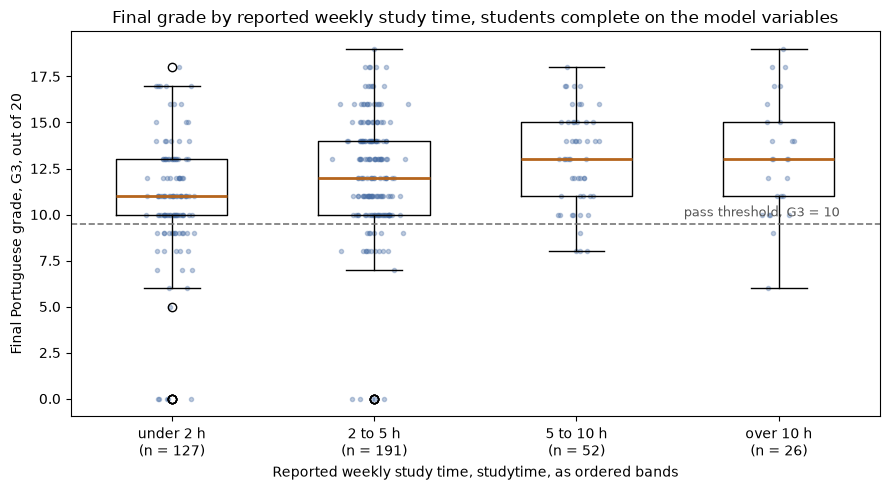

Median final grade by study time band:
           count  median
studytime               
1            127    11.0
2            191    12.0
3             52    13.0
4             26    13.0


In [27]:
# studytime was classified as ordinal in A9, its four codes labelling bands of
# unequal width. Medians and quartiles are therefore shown rather than means or a
# fitted line, following the treatment Unit 5 sets out for ordered categories. The
# zero grades are retained here and marked, so that their effect on the lower
# quartile of each band can be seen rather than silently removed.

STUDY_TIME_BAND_LABELS = {1: "under 2 h", 2: "2 to 5 h", 3: "5 to 10 h", 4: "over 10 h"}

grades_by_study_time_band = [
    students_complete_on_model_variables.loc[
        students_complete_on_model_variables["studytime"] == band, "G3"].values
    for band in sorted(STUDY_TIME_BAND_LABELS)]

figure, axes = plt.subplots(figsize=(9, 5))

axes.boxplot(grades_by_study_time_band, widths=0.55, showmeans=False,
             medianprops=dict(linewidth=2.0, color="#b5651d"))
jitter_generator = np.random.default_rng(0)
for position, band_grades in enumerate(grades_by_study_time_band, start=1):
    axes.scatter(jitter_generator.normal(position, 0.055, len(band_grades)),
                 band_grades, s=9, alpha=0.35, color="#4a6fa5", zorder=1)

axes.axhline(9.5, linestyle="--", linewidth=1.2, color="#777777")
axes.annotate("pass threshold, G3 = 10", xy=(4.3, 9.9), fontsize=9, color="#555555",
              ha="right")

axes.set_xticks(range(1, len(STUDY_TIME_BAND_LABELS) + 1))
axes.set_xticklabels([f"{STUDY_TIME_BAND_LABELS[band]}\n(n = {len(grades)})"
                      for band, grades in zip(sorted(STUDY_TIME_BAND_LABELS),
                                              grades_by_study_time_band)])
axes.set_xlabel("Reported weekly study time, studytime, as ordered bands")
axes.set_ylabel("Final Portuguese grade, G3, out of 20")
axes.set_title("Final grade by reported weekly study time, students complete on the model variables")

plt.tight_layout()
plt.show()

print("Median final grade by study time band:")
print(students_complete_on_model_variables.groupby("studytime")["G3"].agg(["count", "median"]))

---

## AI use

| Part | AI used? | Tool | What it produced | How you checked it |
|---|---|---|---|---|
| A to D, the answers box | Yes | Claude (Anthropic), in Claude Code | The helper functions and the code in every answer cell | Each statistic was recomputed by a second route and the two compared: scipy against the formulae written out by hand for Welch's t, its degrees of freedom, Cohen's d and Cramer's V, and against the independent pure-Python implementations in phase1.py for the pooled d and the Yates-corrected chi-square. A1 to A3 and D2 were checked against the printed counts of missing values. The group used in Parts B to D was verified to be the group counted in A2. |
| E, the short answers | Yes | Claude (Anthropic), in Claude Code | First drafts of the four answers | Every figure quoted was read back from this notebook's own output rather than from the draft. The claim that the zero grades are administrative was tested by inspecting those students' G1, G2 and absences directly. The statement about the sampling procedure was checked against the brief and against the acceptance conditions in phase1.py. Each answer was counted against the hundred word limit using the counting rule the brief specifies. |
| F, the figures | Yes | Claude (Anthropic), in Claude Code | The plotting code for both figures | Bin edges were checked to confirm that a grade of zero occupies its own bar, and the annotated count of zeros was checked against A5. The group sizes printed under Figure 2 were checked against the value counts of studytime. Both axis labels on each figure were read against what the axis actually shows. |

---

## Submit

Run the whole notebook from the top, then check the output of this cell. It
checks the answers box only; your short answers, figures and AI record are read
from the notebook itself. If it ends **NOT READY**, fix what it lists and run the
whole notebook again. Submit the notebook with this output showing.

In [28]:
phase1.submit(ANSWERS)

===== MATH9102 PHASE 1 ANSWERS BEGIN =====
{
 "student_number": "A00083047",
 "fingerprint": "81acda2d",
 "version": "2026.2",
 "answers": {
  "A1_n_students": 420,
  "A2_n_complete_model": 396,
  "A3_n_complete_all": 298,
  "A4_most_missing": "reason",
  "A5_n_g3_zero": 11,
  "A6_r_g2_g3": 0.904,
  "A7_skew_absences": 2.09,
  "A8_early_grades": "b",
  "A9_studytime_level": "c",
  "B1_spearman_absences_g3": -0.154,
  "B2_welch_t_sex": 3.22,
  "B3_welch_p_sex": 0.001,
  "B4_d_sex": 0.33,
  "B5_kw_h_mjob": 24.22,
  "B6_eta2h_mjob": 0.052,
  "B7_chi2_school_higher": 11.83,
  "B8_v_school_higher": 0.181,
  "C1_d_sex_nonzero": 0.37,
  "C2_zeros_change_d": "larger",
  "D1_colleague_d": 0.18,
  "D2_colleague_lost": 98,
  "D3_colleague_shapiro": "d"
 }
}
===== MATH9102 PHASE 1 ANSWERS END =====

22 of 22 items answered.
Every item can be read. This checks the answers box only, and not whether its answers are right. Your short answers, figures and AI record are read from the notebook itself.
